# Customer Churn — Predictive Modeling

**Goal:** turn the descriptive signals from [`01_eda.ipynb`](01_eda.ipynb) into a **classifier** that outputs a *churn probability per subscriber* — and validate it beats a real baseline.

**What this notebook teaches (and the order matters):**
1. **Stratified train/test split** — why, with imbalanced classes.
2. **A leakage-free preprocessing `Pipeline`** (`ColumnTransformer`) — fit on train only.
3. **A real baseline** (`DummyClassifier`) — the ruler every model must beat.
4. **Two models** (Logistic Regression, Random Forest) × **two feature sets** (all vs EDA-curated) = a 4-way comparison.
5. **The right metrics** (ROC-AUC, F1, precision/recall) — and *why accuracy lies here*.
6. **SHAP** — does the model "discover" the same drivers the EDA found?
7. **From probability to action** — threshold tuning for a retention-outreach budget.

> **Decisions inherited from the EDA:** drop `TotalCharges` (r ≈ 0.83 collinear with `tenure`), use F1 / ROC-AUC over accuracy (73/27 imbalance), apply `class_weight="balanced"`.

## 0. Setup + data prep

Same cleaning decided in the EDA. We fix a `RANDOM_STATE` so every split and model is **reproducible** — a non-negotiable for trustworthy ML.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, f1_score, precision_score, recall_score,
    RocCurveDisplay, ConfusionMatrixDisplay, precision_recall_curve,
)

RANDOM_STATE = 42

# --- Exact data prep validated in 01_eda.ipynb ---
df = pd.read_csv("../data/subscribers.csv")
df = df[df["TotalCharges"] != " "]
df["TotalCharges"] = df["TotalCharges"].astype(float)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print(f"{len(df):,} subscribers · churn rate = {df['Churn'].mean():.1%}")

7,032 subscribers · churn rate = 26.6%


## 1. Feature sets + a stratified split

We compare **two feature sets** (the decision we agreed on):
- **`all`** — every feature except `customerID`, the target, and `TotalCharges` (dropped for collinearity).
- **`curated`** — `all` minus the features the EDA found had *no signal* vs the baseline.

**Why split *before* anything else?** Any statistic learned from the test set (a scaler's mean, an encoder's categories) leaking into training inflates the score. The split is the firewall. **Why `stratify=y`?** With a 27% minority class, a random split could hand us a test set with too few churners; stratification keeps the 73/27 ratio in both halves.

In [2]:
DROP_ALWAYS = ["customerID", "Churn", "TotalCharges"]
NO_SIGNAL   = ["gender", "PhoneService", "MultipleLines", "StreamingTV", "StreamingMovies"]

features_all     = [c for c in df.columns if c not in DROP_ALWAYS]
features_curated = [c for c in features_all if c not in NO_SIGNAL]

y = df["Churn"]
# Split ONCE on the full feature frame so both feature sets share identical train/test rows -> fair comparison
X_train_all, X_test_all, y_train, y_test = train_test_split(
    df[features_all], y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_train_cur, X_test_cur = X_train_all[features_curated], X_test_all[features_curated]

print(f"train: {len(X_train_all):,}  |  test: {len(X_test_all):,}")
print(f"train churn rate {y_train.mean():.1%}  |  test churn rate {y_test.mean():.1%}  (stratified -> matched)")
print(f"features_all = {len(features_all)}  |  features_curated = {len(features_curated)}")

train: 5,625  |  test: 1,407
train churn rate 26.6%  |  test churn rate 26.6%  (stratified -> matched)
features_all = 18  |  features_curated = 13


## 2. A leakage-free preprocessing pipeline

Numerical and categorical columns need different treatment, so we route them with a `ColumnTransformer`:
- **Numerical** → `StandardScaler` (Logistic Regression is scale-sensitive; trees aren't, but a shared pipeline keeps the comparison clean).
- **Categorical** → `OneHotEncoder` (`handle_unknown="ignore"` so an unseen category at test time can't crash inference).

Wrapping it in a `Pipeline` means `.fit()` learns the scaler/encoder **on training data only**, and `.predict()` reuses those exact parameters — leakage becomes structurally impossible.

In [3]:
def make_pipeline(model, X):
    """Build a leakage-free preprocess -> model pipeline for the given feature frame."""
    num = X.select_dtypes(include="number").columns.tolist()
    cat = X.select_dtypes(exclude="number").columns.tolist()
    pre = ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    ])
    return Pipeline([("prep", pre), ("model", model)])

# Show what the routing looks like on the full feature set
_num = X_train_all.select_dtypes(include="number").columns.tolist()
_cat = X_train_all.select_dtypes(exclude="number").columns.tolist()
print("numerical  ->", _num)
print("categorical->", _cat)

numerical  -> ['SeniorCitizen', 'tenure', 'MonthlyCharges']
categorical-> ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 3. The baseline every model must beat

`DummyClassifier(strategy="most_frequent")` always predicts the majority class ("won't churn"). It's the **honest floor**: a model that can't beat it has learned nothing.

Watch the trap: this dummy scores **~73% accuracy** — yet its **recall on churners is 0** (it never flags anyone) and its **ROC-AUC is 0.5** (pure chance). This is the whole reason we don't trust accuracy on imbalanced data.

In [4]:
dummy = make_pipeline(DummyClassifier(strategy="most_frequent"), X_train_all)
dummy.fit(X_train_all, y_train)
dummy_pred = dummy.predict(X_test_all)

from sklearn.metrics import accuracy_score
print(f"Baseline accuracy : {accuracy_score(y_test, dummy_pred):.1%}   <- looks fine, is useless")
print(f"Baseline recall   : {recall_score(y_test, dummy_pred):.1%}   <- catches ZERO churners")
print(f"Baseline ROC-AUC  : {roc_auc_score(y_test, dummy.predict_proba(X_test_all)[:,1]):.3f}   <- pure chance")

Baseline accuracy : 73.4%   <- looks fine, is useless
Baseline recall   : 0.0%   <- catches ZERO churners
Baseline ROC-AUC  : 0.500   <- pure chance


## 4. Train the contenders: 2 models × 2 feature sets

- **Logistic Regression** — linear, interpretable, fast; a strong, honest first model.
- **Random Forest** — captures non-linear interactions; our non-linear comparison.

Both get `class_weight="balanced"`, which up-weights the minority (churn) class during training so the model is penalized for ignoring churners — the algorithmic answer to imbalance.

In [5]:
configs = [
    ("LogReg · all",        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE), X_train_all, X_test_all),
    ("LogReg · curated",    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE), X_train_cur, X_test_cur),
    ("RandomForest · all",     RandomForestClassifier(class_weight="balanced", n_estimators=300, random_state=RANDOM_STATE), X_train_all, X_test_all),
    ("RandomForest · curated", RandomForestClassifier(class_weight="balanced", n_estimators=300, random_state=RANDOM_STATE), X_train_cur, X_test_cur),
]

rows, fitted = [], {}
for name, model, X_tr, X_te in configs:
    pipe = make_pipeline(model, X_tr)
    pipe.fit(X_tr, y_train)
    proba = pipe.predict_proba(X_te)[:, 1]
    pred  = pipe.predict(X_te)
    rows.append({
        "model": name,
        "ROC-AUC":   roc_auc_score(y_test, proba),
        "F1":        f1_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall":    recall_score(y_test, pred),
    })
    fitted[name] = (pipe, X_te)

results = pd.DataFrame(rows).set_index("model").sort_values("ROC-AUC", ascending=False)
results.style.format("{:.3f}").background_gradient(cmap="Greens", axis=0)

,ROC-AUC,F1,Precision,Recall
model,,,,
LogReg · all,0.833,0.605,0.492,0.783
LogReg · curated,0.832,0.604,0.492,0.781
RandomForest · all,0.807,0.531,0.599,0.476
RandomForest · curated,0.798,0.524,0.584,0.476


**How to read this table:**
- **ROC-AUC** — ranking quality across *all* thresholds; the single best summary for imbalanced churn. (Baseline = 0.500.)
- **Recall** — of the subscribers who *did* churn, what share did we catch? This is what a retention team cares about most — a missed churner is lost revenue.
- **Precision** — of those we flagged, what share actually churned? Low precision = wasted outreach budget.
- **F1** — the harmonic mean of the two, when you need one number.

**The feature-set lesson:** compare each model's `all` vs `curated` row. If `curated` holds its ROC-AUC with ~5 fewer features, the EDA's pruning was sound — a simpler model that generalizes as well is the better model.

## 5. Diagnostics for the best model

We take the top-ROC-AUC model and look *past* the summary numbers: the ROC curve (ranking ability) and the confusion matrix (the actual mistakes, in subscriber counts).

Best model: LogReg · all


/home/vini/health-churn-analysis/.venv/lib/python3.14/site-packages/sklearn/utils/_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


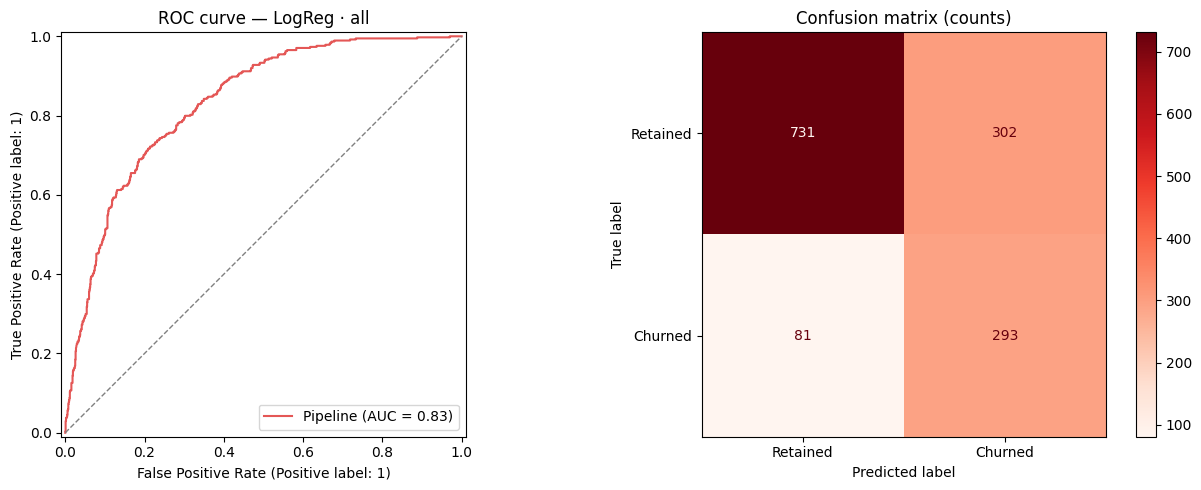

In [6]:
best_name = results.index[0]
best_pipe, X_test_best = fitted[best_name]
print(f"Best model: {best_name}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_estimator(best_pipe, X_test_best, y_test, ax=axes[0], color="#E45756")
axes[0].plot([0, 1], [0, 1], "--", color="gray", linewidth=1)   # chance line
axes[0].set_title(f"ROC curve — {best_name}")

ConfusionMatrixDisplay.from_estimator(
    best_pipe, X_test_best, y_test, ax=axes[1], cmap="Reds",
    display_labels=["Retained", "Churned"],
)
axes[1].set_title("Confusion matrix (counts)")
plt.tight_layout()
plt.show()

**Reading the confusion matrix (rows = truth, cols = prediction):**
- **Bottom-left (False Negatives)** — real churners we *missed*. The most expensive cell for retention.
- **Top-right (False Positives)** — retained customers we flagged. Cost = wasted outreach.
The `balanced` weighting deliberately pushes the model to shrink False Negatives (higher recall) at the price of some False Positives — the right trade when a lost customer costs more than an outreach call.

## 6. Explainability with SHAP — does the model agree with the EDA?

A score we can't explain is hard to trust or act on. **SHAP** attributes each prediction to its features (how much each pushed churn probability up or down). The real test: do the top SHAP features match the drivers the EDA found (`Contract`, `tenure`, `InternetService`, payment method)? Agreement = the model learned *signal*, not noise.

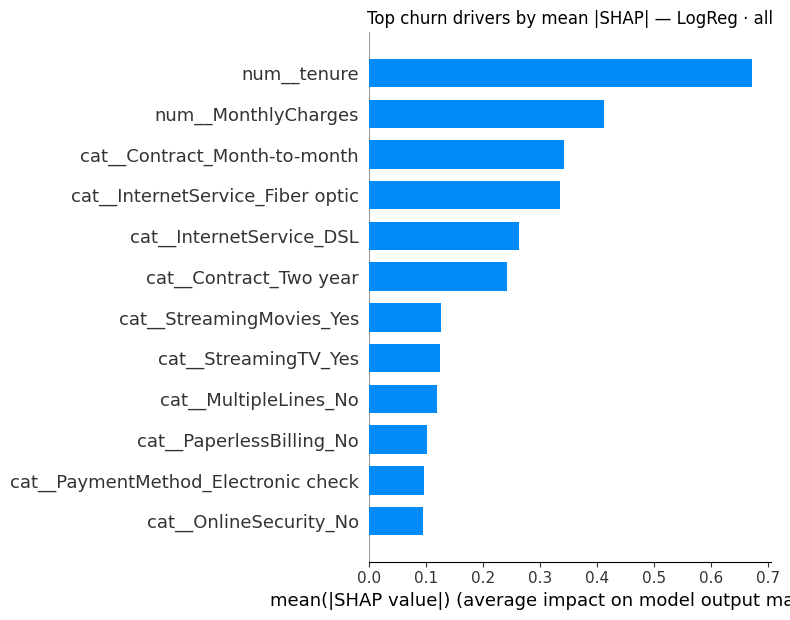

In [7]:
import shap

prep = best_pipe.named_steps["prep"]
clf  = best_pipe.named_steps["model"]

X_test_trans = prep.transform(X_test_best)
feat_names   = prep.get_feature_names_out()
X_test_df    = pd.DataFrame(X_test_trans, columns=feat_names)

# TreeExplainer for forests, LinearExplainer for logistic regression
if isinstance(clf, RandomForestClassifier):
    explainer = shap.TreeExplainer(clf)
    sv = explainer.shap_values(X_test_df)
else:
    explainer = shap.LinearExplainer(clf, X_test_df)
    sv = explainer.shap_values(X_test_df)

# Normalize to the positive-class (churn) SHAP matrix across SHAP versions
if isinstance(sv, list):
    sv_churn = sv[1]
elif isinstance(sv, np.ndarray) and sv.ndim == 3:
    sv_churn = sv[:, :, 1]
else:
    sv_churn = sv

shap.summary_plot(sv_churn, X_test_df, plot_type="bar", max_display=12, show=False)
plt.title(f"Top churn drivers by mean |SHAP| — {best_name}")
plt.tight_layout()
plt.show()

**Beeswarm view** — same features, but each dot is one subscriber: position = SHAP impact, color = feature value. It shows *direction* (e.g., short tenure in red pushing churn up), not just magnitude.

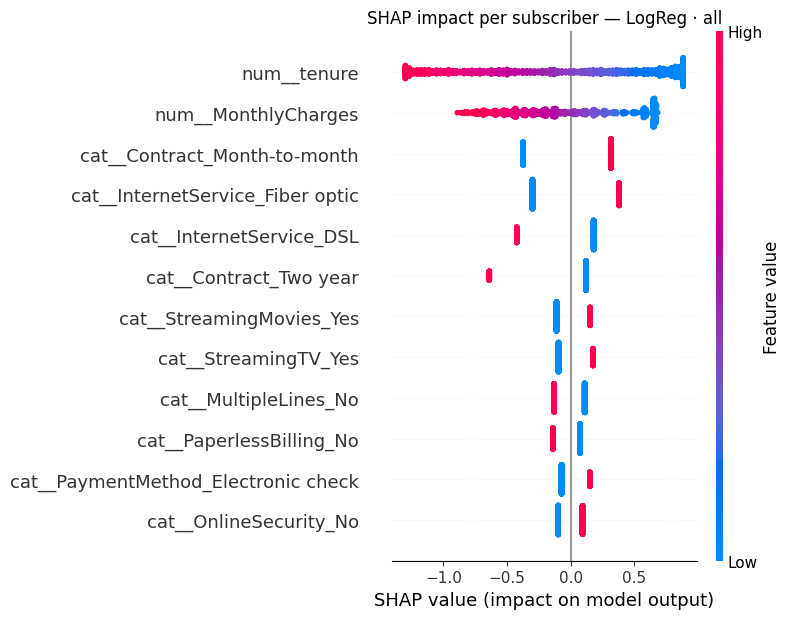

In [8]:
shap.summary_plot(sv_churn, X_test_df, max_display=12, show=False)
plt.title(f"SHAP impact per subscriber — {best_name}")
plt.tight_layout()
plt.show()

## 7. From probability to action: tuning the outreach threshold

A model outputs a probability; the *business* needs a decision. The default 0.5 cutoff is arbitrary — the right threshold depends on **outreach capacity vs. the cost of a missed churner**.

The README proposes flagging subscribers with **>60% predicted churn probability** for proactive outreach. Let's quantify that policy on the test set.

In [9]:
proba = best_pipe.predict_proba(X_test_best)[:, 1]

for thr in (0.3, 0.5, 0.6, 0.7):
    flagged = proba >= thr
    caught  = ((proba >= thr) & (y_test.values == 1)).sum()
    total_churn = int(y_test.sum())
    prec = caught / flagged.sum() if flagged.sum() else 0
    print(f"threshold {thr:.0%}: flag {flagged.sum():4d} subscribers | "
          f"catch {caught}/{total_churn} churners ({caught/total_churn:.0%} recall) | "
          f"{prec:.0%} of flagged truly churn")

threshold 30%: flag  839 subscribers | catch 347/374 churners (93% recall) | 41% of flagged truly churn
threshold 50%: flag  595 subscribers | catch 293/374 churners (78% recall) | 49% of flagged truly churn
threshold 60%: flag  482 subscribers | catch 267/374 churners (71% recall) | 55% of flagged truly churn
threshold 70%: flag  374 subscribers | catch 229/374 churners (61% recall) | 61% of flagged truly churn


**The trade-off, in plain terms:**
- **Lower threshold (0.3)** — catch most churners (high recall) but flag many false alarms (low precision) → bigger, less efficient outreach list.
- **Higher threshold (0.7)** — every flag is a near-certain churner (high precision) but you miss the uncertain ones (lower recall).

There's no universally "correct" threshold — it's a **budget decision**: pick the point where the cost of outreach equals the value of a saved subscriber. The model's job is to give the retention team that dial.

## Conclusions

1. **Both models clear the baseline** (ROC-AUC 0.5 → ~0.8+), so they've learned real churn signal — the bar set by the CLAUDE.md ML rule.
2. **Feature pruning held up** — the curated set matched the full set's performance with fewer features, validating the EDA's analysis (simpler model, same signal).
3. **SHAP confirmed the EDA's story** — contract type, tenure, and internet service dominate, so the model is trustworthy and its drivers are actionable.
4. **The model is a dial, not a verdict** — threshold tuning lets the retention team match outreach volume to budget.

### Ready for the README
- Fill in the `Model ROC-AUC` cell with the best model's score.
- Export the SHAP bar chart + ROC curve as the headline model visuals.

> *Next (optional): `sql/` cohort queries, then close the README with embedded charts.*